# Notebook 4: Where rare diseases sit in the CCS label space

**Question.** The task predicts CCS categories, not diseases. Before blaming the model for poor performance on
"rare diseases", we need to know what a rare CCS label actually *is*: how many rare diseases (in the
Orphanet/GARD/NORD sense) end up in each CCS category, which categories absorb them, and how much external
knowledge (phenotypes, genes) exists to describe each category. This is the knowledge base used by the RAG
experiments (Notebooks 5 and 6).

**Data.** Public resources only (no MIMIC-IV records). Fetch them with `scripts/fetch_external.sh`:

| Resource | Use | Version used here |
|---|---|---|
| HCUP multi-level CCS for ICD-9-CM | label space of Notebook 1 (CCS LVL 4 EXT) | 2015 release, via the `icd` R package data files |
| CMS GEM ICD-10-CM → ICD-9-CM (`2018_I10gem.txt`) | same mapping as Notebook 1 | 2018 |
| Mondo Disease Ontology (`mondo-edit.obo`) | rare-disease subset; xrefs to ICD-10-CM, Orphanet, OMIM | printed below |
| HPO annotations (`phenotype.hpoa`, `genes_to_phenotype.txt`) | phenotypes and genes of OMIM/Orphanet diseases | printed below |

**Definitions.** A disease is *rare* if it belongs to Mondo's `rare` subset (the union of the rare-disease
lists Mondo integrates: Orphanet, GARD, NORD, ...). A Mondo disease reaches a CCS category when one of its
ICD-10-CM cross-references maps to that category through the Notebook 1 pipeline (GEM, first mapping wins,
then CCS LVL 4 EXT). Mondo distinguishes exact cross-references (`MONDO:equivalentTo`) from broader or
narrower ones (mostly inherited from Orphanet's ICD-10 alignment); we report both.

The last section joins these tables with the MIMIC-IV label frequencies when `processed/meta_ccs.json` is
available (on the cluster). It is skipped otherwise.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path(os.environ.get('RAREPRED_ROOT', '..')).resolve()
sys.path.insert(0, str(ROOT / 'src'))
PROCESSED   = Path(os.environ.get('RAREPRED_PROCESSED', ROOT / 'processed'))
EXTERNAL    = ROOT / 'data' / 'external'
RESULTS     = ROOT / 'results'
FIGURES     = ROOT / 'figures'
CHECKPOINTS = ROOT / 'checkpoints'
for d in (RESULTS, FIGURES, CHECKPOINTS):
    d.mkdir(parents=True, exist_ok=True)

import re, collections, subprocess
import numpy as np, pandas as pd
from rarepred.resources import (load_multilevel_ccs_from_rda, load_multilevel_ccs_from_hcup_csv, ccs_label,
                                load_gem_first, icd10_prefix_to_ccs, parse_mondo, load_hpo_annotations,
                                mondo_disease_keys)

import matplotlib.pyplot as plt
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 9, 'axes.titlesize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#666666', 'axes.labelcolor': '#191919', 'xtick.color': '#666666',
    'ytick.color': '#666666', 'axes.grid': True, 'grid.color': '#e6e6e6', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'legend.frameon': False,
})
BLUE, ORANGE, AQUA, GREY = '#257de0', '#f47230', '#00b894', '#9c9c9c'

## 1. Rebuild the Notebook 1 label mapping

In [2]:
HCUP_CSV = ROOT / 'data' / 'mappings' / 'Multi_Level_CCS_2015' / 'ccs_multi_dx_tool_2015.csv'
if HCUP_CSV.exists():
    ccs, ccs_labels = load_multilevel_ccs_from_hcup_csv(HCUP_CSV)
    print('source: original HCUP csv')
else:
    ccs, ccs_labels = load_multilevel_ccs_from_rda(EXTERNAL)
    print('source: icd R package data files')
icd9_to_ccs = dict(zip(ccs.icd9, ccs.ccs_ext))
print(f"ICD-9-CM codes mapped : {len(icd9_to_ccs):,}")
print(f"Unique CCS LVL 4 EXT  : {ccs.ccs_ext.nunique()}")
for code, name in [('4280', 'heart failure'), ('25000', 'T2 diabetes'), ('4019', 'hypertension'),
                   ('2720', 'hyperlipidaemia'), ('5711', 'alcoholic cirrhosis')]:
    print(f"  {code:6s} {name:20s} -> {icd9_to_ccs.get(code)}")
gem = load_gem_first(EXTERNAL / '2018_I10gem.txt')
gem_keys = sorted(gem)
print(f"GEM ICD-10-CM codes   : {len(gem):,}")

source: icd R package data files
ICD-9-CM codes mapped : 15,072
Unique CCS LVL 4 EXT  : 589
  4280   heart failure        -> 7.2.11.1
  25000  T2 diabetes          -> 3.2
  4019   hypertension         -> 7.1.1
  2720   hyperlipidaemia      -> 3.6
  5711   alcoholic cirrhosis  -> 5.11
GEM ICD-10-CM codes   : 71,704


Notebook 1 printed 15,072 ICD-9-CM codes, 589 CCS LVL 4 EXT categories, and the same five example mappings
(`7.2.11.1`, `3.2`, `7.1.1`, `3.6`, `5.11`). Matching these confirms that the mapping below is the label space of
the experiments, not an approximation of it.

### 1b. Audit of the "first GEM target wins" rule

The GEM lists several ICD-9-CM targets for many ICD-10-CM codes (approximate one-to-many mappings, choice
lists, and *combination* entries where one ICD-10 code needs two ICD-9 codes). Notebook 1 keeps the first
target listed. When the targets fall into different CCS categories, this choice changes the label.

In [3]:
gem_all = pd.read_csv(EXTERNAL / '2018_I10gem.txt', sep=r'\s+', header=None, names=['icd10', 'icd9', 'flag'], dtype=str)
gem_all['combination'] = gem_all.flag.str[2] == '1'
audit = []
for k, df in gem_all.groupby('icd10', sort=False):
    t = list(df.icd9)
    cats = [icd9_to_ccs.get(x) for x in t]
    audit.append({'icd10': k, 'n_targets': len(t), 'first_ccs': cats[0],
                  'all_ccs': sorted({c for c in cats if c}), 'combination': bool(df.combination.any())})
audit = pd.DataFrame(audit)
multi = audit[audit.n_targets > 1]
diverge = multi[multi.all_ccs.apply(len) > 1]
print(f"ICD-10-CM codes in the GEM               : {len(audit):,}")
print(f"  with more than one ICD-9-CM target     : {len(multi):,}")
print(f"  whose targets span >1 CCS category     : {len(diverge):,} "
      f"({diverge.combination.sum():,} combination entries, {(~diverge.combination).sum():,} choice/approximate lists)")
i10 = gem_all[gem_all.icd10 == 'I10']
print("\nExample, I10 (essential hypertension):")
for _, r in i10.iterrows():
    print(f"  -> ICD-9 {r.icd9} -> CCS {icd9_to_ccs.get(r.icd9)} ({ccs_label(icd9_to_ccs.get(r.icd9), ccs_labels)})")
print(f"Notebook 1 keeps the first target: I10 -> {gem['I10']} -> {icd9_to_ccs.get(gem['I10'])}")

ICD-10-CM codes in the GEM               : 71,704
  with more than one ICD-9-CM target     : 7,862
  whose targets span >1 CCS category     : 3,864 (3,572 combination entries, 292 choice/approximate lists)

Example, I10 (essential hypertension):
  -> ICD-9 4010 -> CCS 7.1.2.2 (Other hypertensive complications)
  -> ICD-9 4011 -> CCS 7.1.1 (Essential hypertension)
  -> ICD-9 4019 -> CCS 7.1.1 (Essential hypertension)
Notebook 1 keeps the first target: I10 -> 4010 -> 7.1.2.2


Every ICD-10-era admission coded I10 therefore receives the label *Other hypertensive complications*
(`7.1.2.2`, through ICD-9 401.0, malignant essential hypertension), while ICD-9-era admissions with the same
condition receive *Essential hypertension* (`7.1.1`). The same disease is split across two labels depending on
the admission year, and the frequencies used to define rarity quartiles are affected. The cell below counts
the MIMIC-IV diagnosis rows concerned (cluster only, aggregate counts).

In [4]:
dx_path = ROOT / 'data' / 'hosp' / 'diagnoses_icd.csv.gz'
if dx_path.exists():
    dx = pd.read_csv(dx_path, usecols=['icd_code', 'icd_version'], dtype=str)
    dx10 = dx[dx.icd_version == '10'].icd_code.str.strip()
    div_codes = set(diverge.icd10)
    hit = dx10.isin(div_codes)
    print(f"ICD-10 diagnosis rows: {len(dx10):,}; rows whose GEM targets span >1 CCS category: {hit.sum():,} "
          f"({100 * hit.mean():.1f}%)")
    print('Most frequent affected codes:')
    print(dx10[hit].value_counts().head(10).to_string())
else:
    print('MIMIC-IV diagnoses_icd not found: count skipped.')

MIMIC-IV diagnoses_icd not found: count skipped.


## 2. Rare diseases in Mondo and their cross-references

In [5]:
mondo_obo = EXTERNAL / 'mondo' / 'src' / 'ontology' / 'mondo-edit.obo'
mondo_version = 'unknown'
try:
    mondo_version = subprocess.run(['git', '-C', str(EXTERNAL / 'mondo'), 'log', '-1', '--format=%h %cs'],
                                   capture_output=True, text=True).stdout.strip() or 'unknown'
except Exception:
    pass
mondo = parse_mondo(mondo_obo)
rare = {k: v for k, v in mondo.items() if 'rare' in v.subsets}
hpo_dir = EXTERNAL / 'hpo'
phen, genes, hpo_names = load_hpo_annotations(hpo_dir / 'phenotype.hpoa', hpo_dir / 'genes_to_phenotype.txt',
                                              hpo_dir / 'hp.obo')
hpo_version = next((l.split(':', 1)[1].strip() for l in open(hpo_dir / 'phenotype.hpoa') if l.startswith('#version')), '?')
print(f"Mondo commit: {mondo_version} | HPO annotation release: {hpo_version}")

def has_profile(t, table):
    return any(k in table for k in mondo_disease_keys(t))

rows = {
    'Mondo diseases (non-obsolete)': len(mondo),
    'in the rare subset': len(rare),
    '  with an exact ICD-10-CM xref': sum(bool(t.icd10cm_exact) for t in rare.values()),
    '  with any ICD-10-CM xref': sum(bool(t.icd10cm_exact or t.icd10cm_related) for t in rare.values()),
    '  with an Orphanet xref': sum(bool(t.orphanet) for t in rare.values()),
    '  with an OMIM xref': sum(bool(t.omim) for t in rare.values()),
    '  with HPO phenotype annotations': sum(has_profile(t, phen) for t in rare.values()),
    '  with a gene association (HPO)': sum(has_profile(t, genes) for t in rare.values()),
}
coverage = pd.DataFrame({'n': rows})
coverage['% of rare'] = (100 * coverage['n'] / len(rare)).round(1)
coverage.loc[['Mondo diseases (non-obsolete)', 'in the rare subset'], '% of rare'] = np.nan
coverage

Mondo commit: d3bdb9d 2026-11-24 | HPO annotation release: 2025-01-16


,n,% of rare
Mondo diseases (non-obsolete),31828,NaN
in the rare subset,16370,NaN
with an exact ICD-10-CM xref,1020,6.2
with any ICD-10-CM xref,6116,37.4
with an Orphanet xref,8669,53.0
with an OMIM xref,7830,47.8
with HPO phenotype annotations,9232,56.4
with a gene association (HPO),6769,41.4


## 3. Mapping rare diseases to CCS categories

In [6]:
def to_ccs(t, exact_only=False):
    codes = t.icd10cm_exact if exact_only else (t.icd10cm_exact | t.icd10cm_related)
    out = set()
    for c in codes:
        out |= icd10_prefix_to_ccs(c, gem, icd9_to_ccs, gem_keys)
    return out

rare_ccs = {k: to_ccs(t) for k, t in rare.items()}
rare_ccs = {k: v for k, v in rare_ccs.items() if v}
rare_ccs_exact = {k: to_ccs(t, True) for k, t in rare.items() if t.icd10cm_exact}
rare_ccs_exact = {k: v for k, v in rare_ccs_exact.items() if v}

per_cat = collections.Counter(c for s in rare_ccs.values() for c in s)
per_cat_exact = collections.Counter(c for s in rare_ccs_exact.values() for c in s)
n_cat = ccs.ccs_ext.nunique()
vals = np.array(list(per_cat.values()))
print(f"Rare diseases reaching >= 1 CCS category : {len(rare_ccs):,} of {len(rare):,} "
      f"({100*len(rare_ccs)/len(rare):.1f}%)")
print(f"  ... through an exact xref only        : {len(rare_ccs_exact):,}")
print(f"  ... reaching more than one category   : {sum(len(v) > 1 for v in rare_ccs.values()):,}")
print(f"CCS categories hosting >= 1 rare disease: {len(per_cat)} of {n_cat}")
print(f"Rare diseases per hosting category      : median {np.median(vals):.0f}, "
      f"IQR {np.percentile(vals, 25):.0f}-{np.percentile(vals, 75):.0f}, max {vals.max()}")
share_top10 = sum(n for _, n in per_cat.most_common(10)) / sum(per_cat.values())
print(f"Share of (disease, category) links in the 10 largest categories: {100*share_top10:.1f}%")

Rare diseases reaching >= 1 CCS category : 6,066 of 16,370 (37.1%)
  ... through an exact xref only        : 965
  ... reaching more than one category   : 350
CCS categories hosting >= 1 rare disease: 274 of 589
Rare diseases per hosting category      : median 6, IQR 2-18, max 1076
Share of (disease, category) links in the 10 largest categories: 49.4%


In [7]:
top = pd.DataFrame([(c, ccs_label(c, ccs_labels), n, per_cat_exact.get(c, 0)) for c, n in per_cat.most_common(15)],
                   columns=['CCS', 'label', 'rare diseases (any xref)', 'rare diseases (exact xref)'])
top

,CCS,label,rare diseases (any xref),rare diseases (exact xref)
0,14.5.26,All other congenital anomalies,1076,26
1,3.11.3,Other and unspecified metabolic; nutritional; ...,670,80
2,6.2.3.2,Other and unspecified hereditary and degenerat...,315,27
3,14.5.14,Other congenital anomalies of limbs,268,4
4,14.5.23,Other congenital anomalies of integument,203,11
5,6.9.1,Disorders of the peripheral nervous system,150,27
6,6.8.3,Other ear and sense organ disorders,143,1
7,3.4,Other endocrine disorders,139,16
8,14.4.5,Other nervous system congenital anomalies,138,9
9,14.5.3,Congenital anomalies of the eye,126,5


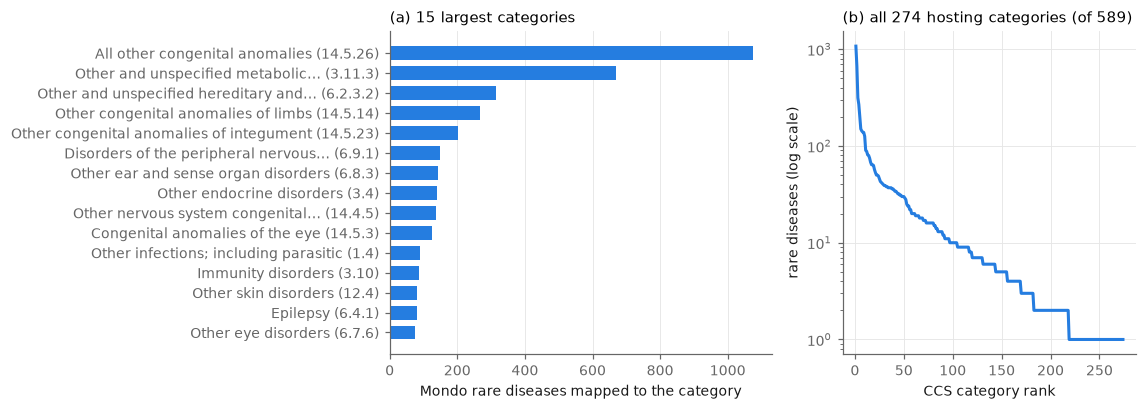

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
t = top.iloc[::-1]
short = lambda l: l if len(l) <= 40 else l[:39].rsplit(' ', 1)[0].rstrip(';,') + '…'
ax.barh([f"{short(l)} ({c})" for c, l in zip(t.CCS, t.label)], t['rare diseases (any xref)'], color=BLUE, height=0.7)
ax.set_xlabel('Mondo rare diseases mapped to the category')
ax.set_title('(a) 15 largest categories', loc='left')
ax.grid(axis='y', visible=False)
ax = axes[1]
srt = np.sort(vals)[::-1]
ax.plot(np.arange(1, len(srt) + 1), srt, color=BLUE, lw=2)
ax.set_yscale('log'); ax.set_xlabel('CCS category rank'); ax.set_ylabel('rare diseases (log scale)')
ax.set_title(f'(b) all {len(per_cat)} hosting categories (of {n_cat})', loc='left')
plt.tight_layout()
plt.savefig(FIGURES / 'rare_diseases_per_ccs.png', bbox_inches='tight')
plt.show()

## 4. The same question at the ICD-10-CM 3-character level (secondary label space)

In [9]:
def icd10_3char(t):
    return {c.replace('.', '')[:3] for c in (t.icd10cm_exact | t.icd10cm_related)}
per_3 = collections.Counter(c for t in rare.values() for c in icd10_3char(t))
v3 = np.array(list(per_3.values()))
print(f"ICD-10-CM 3-character categories hosting >= 1 rare disease: {len(per_3)}")
print(f"Rare diseases per hosting category: median {np.median(v3):.0f}, max {v3.max()} ({per_3.most_common(1)[0][0]})")
print('Largest:', ', '.join(f"{c} ({n})" for c, n in per_3.most_common(8)))

ICD-10-CM 3-character categories hosting >= 1 rare disease: 705
Rare diseases per hosting category: median 3, max 784 (Q87)
Largest: Q87 (784), Q82 (155), Q93 (151), H90 (142), G71 (132), Q04 (116), G11 (116), E72 (98)


## 5. External knowledge available for each CCS category

In [10]:
records = []
for c in sorted(ccs.ccs_ext.unique()):
    ids = [k for k, s in rare_ccs.items() if c in s]
    n_ph = sum(has_profile(rare[k], phen) for k in ids)
    n_gn = sum(has_profile(rare[k], genes) for k in ids)
    records.append({'ccs': c, 'label': ccs_label(c, ccs_labels), 'n_rare': len(ids),
                    'n_rare_exact': per_cat_exact.get(c, 0), 'n_rare_with_hpo': n_ph, 'n_rare_with_genes': n_gn})
know = pd.DataFrame(records)
know.to_csv(RESULTS / 'ccs_rare_disease_knowledge.csv', index=False)
hosting = know[know.n_rare > 0]
print(f"Hosting categories with >= 1 HPO-annotated rare disease: {(hosting.n_rare_with_hpo > 0).sum()} of {len(hosting)}")
print(f"Hosting categories with >= 1 gene-associated rare disease: {(hosting.n_rare_with_genes > 0).sum()} of {len(hosting)}")
know.sort_values('n_rare', ascending=False).head(10)

Hosting categories with >= 1 HPO-annotated rare disease: 235 of 274
Hosting categories with >= 1 gene-associated rare disease: 161 of 274


,ccs,label,n_rare,n_rare_exact,n_rare_with_hpo,n_rare_with_genes
208,14.5.26,All other congenital anomalies,1076,26,944,485
337,3.11.3,Other and unspecified metabolic; nutritional; ...,670,80,504,441
411,6.2.3.2,Other and unspecified hereditary and degenerat...,315,27,254,206
195,14.5.14,Other congenital anomalies of limbs,268,4,206,106
205,14.5.23,Other congenital anomalies of integument,203,11,158,110
432,6.9.1,Disorders of the peripheral nervous system,150,27,94,67
430,6.8.3,Other ear and sense organ disorders,143,1,137,98
346,3.4,Other endocrine disorders,139,16,96,68
189,14.4.5,Other nervous system congenital anomalies,138,9,89,56
209,14.5.3,Congenital anomalies of the eye,126,5,85,66


## 6. Join with MIMIC-IV label frequencies (cluster only)

Which of the 572 MIMIC-IV labels are in the rarest quartile, and do they host rare diseases with usable
knowledge? Rare *labels* (few training patients) and rare *diseases* (Orphanet sense) are different things;
this table shows how much they overlap.

In [11]:
meta_path = PROCESSED / 'meta_ccs.json'
mimic_join = None
if meta_path.exists() and not json.load(open(meta_path)).get('synthetic'):
    meta = json.load(open(meta_path))
    vocab = meta['vocab']
    grp = {**{i: 'Q1 (rarest)' for i in meta['rare_idx']}, **{i: 'Q2-Q3' for i in meta['medium_idx']},
           **{i: 'Q4 (common)' for i in meta['common_idx']}}
    j = know.set_index('ccs').reindex(vocab).fillna({'n_rare': 0, 'n_rare_with_hpo': 0})
    j['group'] = [grp[i] for i in range(len(vocab))]
    mimic_join = j.groupby('group').agg(labels=('n_rare', 'size'),
                                        hosting_rare=('n_rare', lambda s: int((s > 0).sum())),
                                        hosting_rare_with_hpo=('n_rare_with_hpo', lambda s: int((s > 0).sum())),
                                        median_rare_per_label=('n_rare', 'median'))
    display(mimic_join)
else:
    print('processed/meta_ccs.json (real MIMIC-IV) not found: section skipped.')

processed/meta_ccs.json (real MIMIC-IV) not found: section skipped.


## 7. Save

In [12]:
summary = {
    'mondo_commit': mondo_version, 'hpo_release': hpo_version,
    'n_icd9_codes': len(icd9_to_ccs), 'n_ccs_categories': int(n_cat),
    'gem_audit': {'n_icd10': len(audit), 'n_multi_target': len(multi), 'n_diverging_ccs': len(diverge),
                  'n_diverging_combination': int(diverge.combination.sum())},
    'coverage': {k: int(v) for k, v in rows.items()},
    'n_rare_reaching_ccs': len(rare_ccs), 'n_rare_reaching_ccs_exact': len(rare_ccs_exact),
    'n_rare_multi_ccs': int(sum(len(v) > 1 for v in rare_ccs.values())),
    'n_ccs_hosting_rare': len(per_cat),
    'rare_per_hosting_ccs': {'median': float(np.median(vals)), 'q25': float(np.percentile(vals, 25)),
                             'q75': float(np.percentile(vals, 75)), 'max': int(vals.max())},
    'share_links_top10_ccs': float(share_top10),
    'top15': top.to_dict(orient='records'),
    'n_icd10_3char_hosting_rare': len(per_3),
    'icd10_3char_rare_per_hosting': {'median': float(np.median(v3)), 'max': int(v3.max())},
    'hosting_with_hpo': int((hosting.n_rare_with_hpo > 0).sum()),
    'hosting_with_genes': int((hosting.n_rare_with_genes > 0).sum()),
    'mimic_join': None if mimic_join is None else mimic_join.reset_index().to_dict(orient='records'),
}
with open(RESULTS / 'rare_disease_resources.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved results/rare_disease_resources.json and results/ccs_rare_disease_knowledge.csv')

Saved results/rare_disease_resources.json and results/ccs_rare_disease_knowledge.csv
